In [2]:
import numpy as np
import pandas as pd
import json

# Location of the trained model's results
run_dir = "../runs/20261028-020745_distilroberta-base_e12"

# Load actual labels and predicted probabilities
test_labels = np.load(f"{run_dir}/test_labels.npy")
test_probs = np.load(f"{run_dir}/test_probs.npy")

# Load existing evaluation metrics
metrics = pd.read_csv(f"{run_dir}/per_category_test_metrics.csv")

# Load probability thresholds
with open(f"{run_dir}/thresholds.json") as f:
    thresholds = json.load(f)

print("Actual labels shape:", test_labels.shape)
print("Predicted probabilities shape:", test_probs.shape)

display(metrics.head())

Actual labels shape: (4283, 40)
Predicted probabilities shape: (4283, 40)


,category,n_pos_test,base_rate,threshold,precision,recall,f1,auc,ap,scored
0,No-Solicit Of Employees,18,0.004203,0.469748,0.620690,1.000000,0.765957,0.999505,0.887159,True
1,Governing Law,157,0.036657,0.495003,0.864706,0.936306,0.899083,0.995235,0.886635,True
2,Anti-Assignment,175,0.040859,0.922900,0.920290,0.725714,0.811502,0.983417,0.883959,True
3,Renewal Term,46,0.010740,0.754010,0.750000,0.847826,0.795918,0.998661,0.881522,True
4,Parties,174,0.040626,0.738669,0.826347,0.793103,0.809384,0.965657,0.836595,False


In [3]:
# Use the thresholds already saved in the metrics file
category_names = metrics["category"].tolist()
category_thresholds = metrics["threshold"].to_numpy()

# Convert probabilities into binary predictions
test_predictions = (
    test_probs >= category_thresholds
).astype(int)

# Count errors for each category
false_positives = (
    (test_predictions == 1) & (test_labels == 0)
).sum(axis=0)

false_negatives = (
    (test_predictions == 0) & (test_labels == 1)
).sum(axis=0)

# Build error analysis table
error_summary = pd.DataFrame({
    "category": category_names,
    "false_positives": false_positives,
    "false_negatives": false_negatives,
    "total_errors": false_positives + false_negatives
})

# Show categories with the most errors
display(
    error_summary.sort_values(
        "total_errors", ascending=False
    ).head(10)
)

,category,false_positives,false_negatives,total_errors
10,License Grant,78,61,139
20,Unlimited/All-You-Can-Eat-License,77,48,125
29,Post-Termination Services,59,50,109
28,Rofr/Rofo/Rofn,82,27,109
11,Liquidated Damages,78,26,104
18,Uncapped Liability,52,47,99
5,Expiration Date,47,44,91
15,Non-Compete,49,38,87
9,Agreement Date,39,44,83
31,Affiliate License-Licensee,31,39,70


In [4]:
# Inspect the saved model configuration
with open(f"{run_dir}/config.json") as f:
    config = json.load(f)

print("Configuration keys:")
print(list(config.keys()))

print("\nFirst five metric categories:")
print(category_names[:5])

print("\nSaved thresholds:")
print(str(thresholds)[:1000])

Configuration keys:
['model_name', 'max_length', 'batch_size', 'lr', 'epochs', 'warmup_frac', 'weight_decay', 'seed', 'device', 'amp', 'run_id', 'pos_weight', 'n_fit_chunks', 'n_val_chunks', 'n_test_chunks', 'categories', 'eval_categories', 'val_macro_ap']

First five metric categories:
['No-Solicit Of Employees', 'Governing Law', 'Anti-Assignment', 'Renewal Term', 'Parties']

Saved thresholds:
{'Affiliate License-Licensee': 0.8067004084587097, 'Affiliate License-Licensor': 0.5734395384788513, 'Agreement Date': 0.8810019493103027, 'Anti-Assignment': 0.9229002594947815, 'Audit Rights': 0.8786270022392273, 'Cap On Liability': 0.459682434797287, 'Change Of Control': 0.7459540367126465, 'Competitive Restriction Exception': 0.4353013038635254, 'Covenant Not To Sue': 0.7166153788566589, 'Document Name': 0.9133679866790771, 'Effective Date': 0.6980207562446594, 'Exclusivity': 0.6965778470039368, 'Expiration Date': 0.6606104373931885, 'Governing Law': 0.4950028955936432, 'Insurance': 0.6296607

In [5]:
# Compare the model's category order with our metrics table
model_categories = config["categories"]

print("Number of model categories:", len(model_categories))
print("Number of metric categories:", len(category_names))

print("\nFirst five model categories:")
print(model_categories[:5])

print("\nDo the category orders match?")
print(model_categories == category_names)

Number of model categories: 40
Number of metric categories: 40

First five model categories:
['Affiliate License-Licensee', 'Affiliate License-Licensor', 'Agreement Date', 'Anti-Assignment', 'Audit Rights']

Do the category orders match?
False


In [6]:
# Use the correct category order from the model configuration
category_names = config["categories"]

# Match each category with its saved threshold
category_thresholds = np.array([
    thresholds[category] for category in category_names
])

# Recalculate predictions using the correct thresholds
test_predictions = (
    test_probs >= category_thresholds
).astype(int)

# Recalculate false positives and false negatives
false_positives = (
    (test_predictions == 1) & (test_labels == 0)
).sum(axis=0)

false_negatives = (
    (test_predictions == 0) & (test_labels == 1)
).sum(axis=0)

# Create corrected error summary
error_summary = pd.DataFrame({
    "category": category_names,
    "false_positives": false_positives,
    "false_negatives": false_negatives,
    "total_errors": false_positives + false_negatives
})

# Display the 10 categories with the most errors
display(
    error_summary.sort_values(
        "total_errors", ascending=False
    ).head(10)
)

,category,false_positives,false_negatives,total_errors
10,Effective Date,88,55,143
20,Minimum Commitment,60,55,115
29,Post-Termination Services,59,50,109
5,Cap On Liability,68,35,103
18,License Grant,52,47,99
31,Revenue/Profit Sharing,63,28,91
9,Document Name,36,48,84
11,Exclusivity,49,35,84
7,Competitive Restriction Exception,73,10,83
24,Non-Compete,57,13,70


In [7]:
# Count actual positive examples for each category
actual_positives = test_labels.sum(axis=0)

# Calculate false-negative rates
fn_rates = np.divide(
    false_negatives,
    actual_positives,
    out=np.zeros(len(false_negatives), dtype=float),
    where=actual_positives != 0
)

# Add results to our summary
error_summary["actual_positives"] = actual_positives
error_summary["false_negative_rate"] = fn_rates

# Display categories with the highest miss rates
display(
    error_summary[
        error_summary["actual_positives"] >= 10
    ].sort_values(
        "false_negative_rate", ascending=False
    ).head(10)
)

,category,false_positives,false_negatives,total_errors,actual_positives,false_negative_rate
25,Non-Disparagement,3,13,16,14.0,0.928571
1,Affiliate License-Licensor,9,13,22,18.0,0.722222
0,Affiliate License-Licensee,8,19,27,28.0,0.678571
38,Volume Restriction,23,24,47,38.0,0.631579
15,Ip Ownership Assignment,17,45,62,75.0,0.600000
6,Change Of Control,14,43,57,74.0,0.581081
8,Covenant Not To Sue,6,36,42,66.0,0.545455
22,No-Solicit Of Customers,19,8,27,16.0,0.500000
29,Post-Termination Services,59,50,109,101.0,0.495050
26,Non-Transferable License,14,28,42,57.0,0.491228


In [8]:
# Calculate recall from our predictions
error_summary["recall_calculated"] = (
    1 - error_summary["false_negative_rate"]
)

# Compare against the saved model metrics
comparison = error_summary.merge(
    metrics[["category", "recall"]],
    on="category",
    how="left"
)

comparison["recall_difference"] = abs(
    comparison["recall_calculated"] - comparison["recall"]
)

display(
    comparison[
        ["category", "recall_calculated",
         "recall", "recall_difference"]
    ].sort_values(
        "recall_difference", ascending=False
    ).head(10)
)

,category,recall_calculated,recall,recall_difference
14,Insurance,0.855556,0.855556,1.110223e-16
24,Non-Compete,0.793651,0.793651,1.110223e-16
4,Audit Rights,0.732759,0.732759,1.110223e-16
8,Covenant Not To Sue,0.454545,0.454545,1.110223e-16
34,Termination For Convenience,0.575758,0.575758,1.110223e-16
33,Source Code Escrow,0.666667,0.666667,1.110223e-16
21,Most Favored Nation,0.333333,0.333333,5.551115e-17
38,Volume Restriction,0.368421,0.368421,5.551115e-17
6,Change Of Control,0.418919,0.418919,5.551115e-17
25,Non-Disparagement,0.071429,0.071429,0.000000e+00


## 3. Qualitative Error Analysis

### Investigating False Negatives

After evaluating overall model performance, the next step is to examine
individual classification errors to better understand why they occur.

We begin with the **Non-Disparagement** category because it has one of
the highest false-negative rates in the test dataset.

The model missed 13 of the 14 actual Non-Disparagement examples,
resulting in a false-negative rate of approximately 92.9%.

For each missed example, we will examine:
- The model's predicted probability compared with its classification threshold.
- The actual contract language associated with the missed clause.
- Potential patterns that may explain the incorrect prediction.

The goal is to identify recurring weaknesses and suggest improvements
to the clause-classification pipeline.

In [10]:
# Choose a category with a high false-negative rate
target_category = "Non-Disparagement"

# Find its column in the prediction arrays
category_idx = category_names.index(target_category)

# Find examples where the clause exists but the model missed it
fn_indices = np.where(
    (test_labels[:, category_idx] == 1) &
    (test_predictions[:, category_idx] == 0)
)[0]

print("Category:", target_category)
print("Number of false negatives:", len(fn_indices))

# Display the first five missed examples
for idx in fn_indices[:5]:
    print(
        f"Chunk {idx}: "
        f"Probability = {test_probs[idx, category_idx]:.4f}, "
        f"Threshold = {category_thresholds[category_idx]:.4f}"
    )

Category: Non-Disparagement
Number of false negatives: 13
Chunk 1701: Probability = 0.0728, Threshold = 0.7884
Chunk 1702: Probability = 0.1754, Threshold = 0.7884
Chunk 1824: Probability = 0.1738, Threshold = 0.7884
Chunk 1825: Probability = 0.2593, Threshold = 0.7884
Chunk 1843: Probability = 0.0007, Threshold = 0.7884


### Examining Misclassified Contract Text

While error counts and predicted probabilities help identify where the
model struggles, they do not explain why the errors occur.

To investigate potential causes, we need to connect incorrect predictions
to their corresponding contract text.

This will allow us to examine whether errors are associated with:
- Unusual or complex legal language.
- Similarities between different clause categories.
- Missing context or chunk boundaries.
- Rare clause types with limited training examples.

These are potential explanations that will be evaluated by examining
individual examples rather than assumed in advance.

In [11]:
import os

# Check which processed data files are available
data_dir = "../data/processed"

if os.path.exists(data_dir):
    print("Available processed files:")
    for filename in sorted(os.listdir(data_dir)):
        print(filename)
else:
    print("Processed data directory not found.")

Available processed files:
test_chunks.csv
test_clauses.csv
test_contracts.csv
test_labels.csv
train_chunks.csv
train_clauses.csv
train_contracts.csv
train_labels.csv


In [12]:
# Load the test chunks
test_chunks = pd.read_csv("../data/processed/test_chunks.csv")

print("Number of test chunks:", len(test_chunks))
print("\nAvailable columns:")
print(test_chunks.columns.tolist())

print("\nFirst three rows:")
display(test_chunks.head(3))

Number of test chunks: 4283

Available columns:
['contract_id', 'chunk_id', 'token_start', 'token_end', 'char_start', 'char_end', 'text', 'labels']

First three rows:


,contract_id,chunk_id,token_start,token_end,char_start,char_end,text,labels
0,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,0,0,510,0,2241,Exhibit 10.16 SUPPLY CONTRACT Contract No: Dat...,"[""Document Name"", ""Parties""]"
1,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,1,254,764,1052,3447,"""LEHEYUAN""), to purchase the products specifie...",[]
2,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_...,2,508,1018,2231,4407,subject to the purchase order issued by entrus...,"[""Insurance""]"


In [14]:
# Convert the saved JSON labels into Python lists
chunk_labels = test_chunks["labels"].apply(json.loads)

# Reconstruct the binary label matrix
reconstructed_labels = np.array([
    [int(category in labels) for category in category_names]
    for labels in chunk_labels
])

# Compare reconstructed labels with the model's test labels
print("Reconstructed shape:", reconstructed_labels.shape)
print("Model labels shape:", test_labels.shape)

print(
    "Do all labels match?",
    np.array_equal(reconstructed_labels, test_labels)
)

# Count rows with any mismatched labels
mismatched_rows = np.sum(
    np.any(reconstructed_labels != test_labels, axis=1)
)

print("Rows with mismatched labels:", mismatched_rows)

Reconstructed shape: (4283, 40)
Model labels shape: (4283, 40)
Do all labels match? True
Rows with mismatched labels: 0


### Case Study: Non-Disparagement False Negatives

The reconstructed test labels match the model's saved labels across
all 4,283 chunks, confirming that the datasets are aligned.

We now examine individual false negatives for the Non-Disparagement
category, which has a false-negative rate of approximately 92.9%.

By comparing the model's predicted probabilities with the actual
contract language, we aim to identify recurring patterns that may
explain why these clauses were missed.

In [15]:
# Display the first three missed Non-Disparagement examples
for idx in fn_indices[:3]:
    print("=" * 80)
    print("Test row:", idx)
    print("Contract:", test_chunks.iloc[idx]["contract_id"])
    print("Chunk ID:", test_chunks.iloc[idx]["chunk_id"])

    print(
        "Predicted probability:",
        round(float(test_probs[idx, category_idx]), 4)
    )
    print(
        "Classification threshold:",
        round(float(category_thresholds[category_idx]), 4)
    )

    print("\nActual labels:")
    print(test_chunks.iloc[idx]["labels"])

    print("\nContract text:")
    print(test_chunks.iloc[idx]["text"])

    print("\n")

Test row: 1701
Contract: BerkshireHillsBancorpInc_20120809_10-Q_EX-10.16_7708169_EX-10.16_Endorsement Agreement
Chunk ID: 13
Predicted probability: 0.0728
Classification threshold: 0.7884

Actual labels:
["Non-Disparagement", "Post-Termination Services"]

Contract text:
to the other Party. Whether or not such notice is given, the  other Party shall have the right, to the fullest extent permitted under applicable law, following the occurrence of any Event of Insolvency and  without prejudice to any other rights it may have, at any time thereafter to terminate this Agreement, effective immediately upon giving notice to  the Bankrupt Party.     c) EFFECT OF TERMINATION. Upon the expiration or termination of this Agreement for any reason (i) all payments that have accrued  prior to the termination or expiration of this Agreement will be payable in full within thirty (30) days thereof, but any obligations to make further  payments due, or that may have come due, under this Agreement shall b

### Initial Findings: Non-Disparagement

The first examined false negative reveals a potential weakness in
recognizing clauses embedded within broader contractual provisions.

**Example: Berkshire Hills Endorsement Agreement (Test Row 1701)**

- Actual category: Non-Disparagement
- Predicted probability: 0.0728
- Classification threshold: 0.7884
- Result: False negative

The relevant language states that the agreement may be terminated
if Auriemma publicly disparages Berkshire or its products.

**Potential explanations:**

1. **Indirect clause structure:** The non-disparagement provision
   appears as a condition for termination rather than a standalone
   restriction.
2. **Competing context:** The chunk contains extensive termination
   language, which may make the relevant provision harder to identify.
3. **Clause placement:** The relevant language appears near the end
   of the chunk, surrounded by unrelated contractual provisions.

These observations suggest that the model may struggle with
non-disparagement language embedded within other legal provisions.
Additional examples are needed to determine whether this is a
recurring pattern.

In [16]:
# Summarize all missed Non-Disparagement examples
fn_examples = pd.DataFrame({
    "test_row": fn_indices,
    "contract_id": test_chunks.iloc[fn_indices]["contract_id"].values,
    "chunk_id": test_chunks.iloc[fn_indices]["chunk_id"].values,
    "probability": test_probs[fn_indices, category_idx],
    "threshold": category_thresholds[category_idx],
    "text_preview": [
        text[:250].replace("\n", " ")
        for text in test_chunks.iloc[fn_indices]["text"]
    ]
})

display(fn_examples)

,test_row,contract_id,chunk_id,probability,threshold,text_preview
0,1701,BerkshireHillsBancorpInc_20120809_10-Q_EX-10.1...,13,0.072768,0.78842,to the other Party. Whether or not such notice...
1,1702,BerkshireHillsBancorpInc_20120809_10-Q_EX-10.1...,14,0.175397,0.78842,"ma Identification (collectively, ""Materials""),..."
2,1824,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,20,0.173849,0.78842,"(ii) Such Party becomes insolvent, or takes th..."
3,1825,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,21,0.259263,0.78842,its affiliates in the case of an HOF Entity) i...
4,1843,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,39,0.000704,0.78842,10 Confidentiality. Without limiting the gener...
5,1844,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,40,0.010902,0.78842,hereby. The HOF Entities and Constellation sha...
6,2231,WOMENSGOLFUNLIMITEDINC_03_29_2000-EX-10.13-END...,10,0.019531,0.78842,half of one percent (0.5%) of the Royalty...
7,2232,WOMENSGOLFUNLIMITEDINC_03_29_2000-EX-10.13-END...,11,0.065128,0.78842,claim against the Company. The Company may ele...
8,2233,WOMENSGOLFUNLIMITEDINC_03_29_2000-EX-10.13-END...,12,0.000823,0.78842,5.1.4 acts or omissions re...
9,2603,SoupmanInc_20150814_8-K_EX-10.1_9230148_EX-10....,63,0.663996,0.78842,"any of the provisions of this Section 6, you s..."


### Investigating Repeated Errors Across Contracts

Because the dataset uses overlapping text chunks, the same legal
provision may appear in multiple chunks.

As a result, multiple false negatives do not necessarily represent
multiple distinct clauses.

To better understand the model's weaknesses, we examine how
classification errors are distributed across contracts and identify
whether several mistakes may originate from the same underlying
provision.

In [17]:
# Group Non-Disparagement false negatives by contract
contract_errors = (
    fn_examples.groupby("contract_id")
    .agg(
        missed_chunks=("test_row", "count"),
        chunk_ids=("chunk_id", list),
        avg_probability=("probability", "mean")
    )
    .reset_index()
    .sort_values("missed_chunks", ascending=False)
)

print("Total false-negative chunks:", len(fn_examples))
print("Contracts containing false negatives:", len(contract_errors))

display(contract_errors)

Total false-negative chunks: 13
Contracts containing false negatives: 5


,contract_id,missed_chunks,chunk_ids,avg_probability
1,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,4,"[20, 21, 39, 40]",0.111179
2,Monsanto Company - SECOND A_R EXCLUSIVE AGENCY...,3,"[85, 103, 104]",0.349647
4,WOMENSGOLFUNLIMITEDINC_03_29_2000-EX-10.13-END...,3,"[10, 11, 12]",0.028494
0,BerkshireHillsBancorpInc_20120809_10-Q_EX-10.1...,2,"[13, 14]",0.124083
3,SoupmanInc_20150814_8-K_EX-10.1_9230148_EX-10....,1,[63],0.663996


### Examining Overlapping False Negatives

The 13 Non-Disparagement false-negative chunks originate from
only five contracts.

Because the chunking strategy uses 510-token windows with
256-token overlap, adjacent chunks may contain the same
underlying legal provision.

We examine the token ranges of missed chunks to determine
which errors occur in overlapping windows.

This helps distinguish repeated chunk-level errors from
potentially independent missed clauses.

In [18]:
# Get the original token ranges for each missed chunk
overlap_analysis = test_chunks.iloc[fn_indices][[
    "contract_id",
    "chunk_id",
    "token_start",
    "token_end"
]].copy()

# Sort by contract and chunk position
overlap_analysis = overlap_analysis.sort_values(
    ["contract_id", "token_start"]
)

# Compare each missed chunk with the previous missed chunk
overlap_analysis["previous_end"] = (
    overlap_analysis.groupby("contract_id")["token_end"].shift()
)

overlap_analysis["overlap_tokens"] = (
    overlap_analysis["previous_end"]
    - overlap_analysis["token_start"]
).clip(lower=0).fillna(0).astype(int)

display(overlap_analysis[[
    "contract_id",
    "chunk_id",
    "token_start",
    "token_end",
    "overlap_tokens"
]])

,contract_id,chunk_id,token_start,token_end,overlap_tokens
1701,BerkshireHillsBancorpInc_20120809_10-Q_EX-10.1...,13,3302,3812,0
1702,BerkshireHillsBancorpInc_20120809_10-Q_EX-10.1...,14,3556,4066,256
1824,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,20,5080,5590,0
1825,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,21,5334,5844,256
1843,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,39,9906,10416,0
1844,GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10...,40,10160,10670,256
3392,Monsanto Company - SECOND A_R EXCLUSIVE AGENCY...,85,21590,22100,0
3410,Monsanto Company - SECOND A_R EXCLUSIVE AGENCY...,103,26162,26672,0
3411,Monsanto Company - SECOND A_R EXCLUSIVE AGENCY...,104,26416,26926,256
2603,SoupmanInc_20150814_8-K_EX-10.1_9230148_EX-10....,63,16002,16512,0


### Findings: Overlapping Classification Errors

The overlap analysis identified 13 Non-Disparagement false-negative
chunks distributed across five contracts.

Five of these chunks overlap with a preceding missed chunk by
256 tokens, producing eight groups of overlapping errors.

**Key observations:**

1. Several classification errors occur in adjacent chunks that
   share substantial portions of contract text.
2. Some contracts contain multiple, non-overlapping groups of
   missed chunks.
3. The number of false-negative chunks may overstate the number
   of distinct legal provisions missed.

**Implication:**

Chunk-level evaluation is useful for measuring classifier
performance, but it does not directly measure the number of
unique clauses missed.

Further examination of the underlying contract language is
necessary to distinguish repeated errors from independent
missed provisions.

In [20]:
# Select the first chunk from each non-overlapping error group
representative_indices = overlap_analysis[
    overlap_analysis["overlap_tokens"] == 0
].index.tolist()

print("Number of representative examples:", len(representative_indices))

# Display the first three examples
for idx in representative_indices[:3]:
    row = test_chunks.loc[idx]

    print("=" * 80)
    print("Test row:", idx)
    print("Contract:", row["contract_id"])
    print("Chunk ID:", row["chunk_id"])
    print("Predicted probability:",
          round(float(test_probs[idx, category_idx]), 4))

    print("\nContract text:")
    print(row["text"])
    print()

Number of representative examples: 7
Test row: 1701
Contract: BerkshireHillsBancorpInc_20120809_10-Q_EX-10.16_7708169_EX-10.16_Endorsement Agreement
Chunk ID: 13
Predicted probability: 0.0728

Contract text:
to the other Party. Whether or not such notice is given, the  other Party shall have the right, to the fullest extent permitted under applicable law, following the occurrence of any Event of Insolvency and  without prejudice to any other rights it may have, at any time thereafter to terminate this Agreement, effective immediately upon giving notice to  the Bankrupt Party.     c) EFFECT OF TERMINATION. Upon the expiration or termination of this Agreement for any reason (i) all payments that have accrued  prior to the termination or expiration of this Agreement will be payable in full within thirty (30) days thereof, but any obligations to make further  payments due, or that may have come due, under this Agreement shall become null and void; (ii) except as otherwise provided herein, 

### Initial Qualitative Findings

Examination of the first two representative false negatives suggests
that Non-Disparagement clauses may be difficult to identify when
they appear within broader termination or reputational provisions.

**Example 1: Berkshire Hills Endorsement Agreement**
- The contract permits termination if a party publicly disparages
  the other party or its products.
- The model assigned a probability of 0.0728, below the 0.7884 threshold.
- The relevant language appears within a larger termination section.

**Example 2: GPAQ Service Agreement**
- The contract permits termination when association with another
  party could materially damage its reputation or image.
- The model assigned a probability of 0.1738, below the threshold.
- The language concerns reputational harm without explicitly
  using the word "disparagement."

**Preliminary interpretation:**

The model may struggle to recognize Non-Disparagement clauses when
they are expressed indirectly or embedded within other contractual
provisions.

These observations are preliminary and require additional examples
before identifying a recurring error pattern.

In [21]:
# Display remaining representative examples
for idx in representative_indices[2:]:
    row = test_chunks.loc[idx]

    print("=" * 80)
    print("Test row:", idx)
    print("Contract:", row["contract_id"])
    print("Chunk ID:", row["chunk_id"])
    print(
        "Predicted probability:",
        round(float(test_probs[idx, category_idx]), 4)
    )

    # Search for words associated with non-disparagement
    text = row["text"]
    keywords = [
        "disparag", "reputation", "reputational",
        "negative", "critic", "derogatory"
    ]

    found = False

    for keyword in keywords:
        position = text.lower().find(keyword)

        if position != -1:
            start = max(0, position - 150)
            end = min(len(text), position + 300)

            print(f"\nKeyword: {keyword}")
            print(text[start:end])
            found = True

    if not found:
        print("\nNo matching keywords found.")
        print("Text preview:", text[:700])

    print()

Test row: 1843
Contract: GpaqAcquisitionHoldingsInc_20200123_S-4A_EX-10.8_11951679_EX-10.8_Service Agreement
Chunk ID: 39
Predicted probability: 0.0007

Keyword: disparag
eby. The HOF Entities and Constellation shall mutually agree on the content of any such press release prior to its publication. 6.12 No Defamation or Disparagement. No Party will make, issue or release any statement which results in any defamation or disparagement of the Village, the City of Canton, the other Party, or any team, person, performer or organization involved in events at the Village.

15

Source: GPAQ ACQUISITION HOLDINGS, INC., S-4/

Test row: 3392
Contract: Monsanto Company - SECOND A_R EXCLUSIVE AGENCY AND MARKETING AGREEMENT 
Chunk ID: 85
Predicted probability: 0.0008

Keyword: disparag
of the Natural Products in a manner that is consistent with this Agreement and complementary to Roundup Products, and does not directly or indirectly disparage or advertise against Roundup Products, as set forth in thi

### Finding: Explicit Disparagement Language Is Also Missed

Further examination revealed that the model sometimes fails to
identify Non-Disparagement clauses even when the relevant language
explicitly mentions disparagement.

Examples include:

- GPAQ Service Agreement: "No Defamation or Disparagement"
  (predicted probability: 0.0007).
- Monsanto Marketing Agreement: "does not directly or indirectly
  disparage" (predicted probability: 0.0008).
- Berkshire Hills Endorsement Agreement: "publicly disparages
  Berkshire" (predicted probability: 0.0728).

All three predictions fall substantially below the category's
classification threshold of 0.7884.

**Interpretation:**

The model's difficulty is not limited to indirect references to
reputational harm. It also misses some explicitly worded clauses.

Potential contributing factors include surrounding contractual
context, variation in clause structure, and limited representation
of certain clause types during training.

These remain hypotheses rather than confirmed explanations.

In [23]:
# Load training chunks
train_chunks = pd.read_csv("../data/processed/train_chunks.csv")

# Convert saved labels into lists
train_label_lists = train_chunks["labels"].apply(json.loads)

# Count positive training chunks for each category
train_counts = {
    category: sum(
        category in labels
        for labels in train_label_lists
    )
    for category in category_names
}

# Combine training frequency with model recall
frequency_analysis = pd.DataFrame({
    "category": category_names,
    "train_positives": [
        train_counts[category] for category in category_names
    ]
})

frequency_analysis = frequency_analysis.merge(
    metrics[["category", "recall", "f1"]],
    on="category",
    how="left"
)

# Show the rarest categories
display(
    frequency_analysis.sort_values(
        "train_positives"
    ).head(15)
)

,category,train_positives,recall,f1
37,Unlimited/All-You-Can-Eat-License,34,0.571429,0.571429
33,Source Code Escrow,43,0.666667,0.800000
35,Third Party Beneficiary,50,0.555556,0.465116
21,Most Favored Nation,50,0.333333,0.133333
1,Affiliate License-Licensor,57,0.277778,0.312500
22,No-Solicit Of Customers,61,0.500000,0.372093
25,Non-Disparagement,73,0.071429,0.111111
23,No-Solicit Of Employees,101,1.000000,0.765957
17,Joint Ip Ownership,118,0.611111,0.647059
19,Liquidated Damages,119,0.593750,0.622951


### Finding: Training Frequency and Model Performance

The training dataset contains substantial variation in the number
of positive examples available for different clause categories.

Non-Disparagement has only 73 positive training chunks and
achieves a test recall of approximately 7.1%.

Other relatively uncommon categories also exhibit low recall,
including Affiliate License-Licensor (27.8%) and Most Favored
Nation (33.3%).

However, No-Solicit Of Employees achieves 100% recall with
101 positive training chunks, demonstrating that limited
training frequency does not always result in poor performance.

**Interpretation:**

Class imbalance may contribute to classification errors, but
training frequency alone does not explain the observed differences.

Additional factors may include variation in legal language,
category complexity, and differences in the training examples.

Spearman correlation: 0.4133
P-value: 0.008


Matplotlib is building the font cache; this may take a moment.


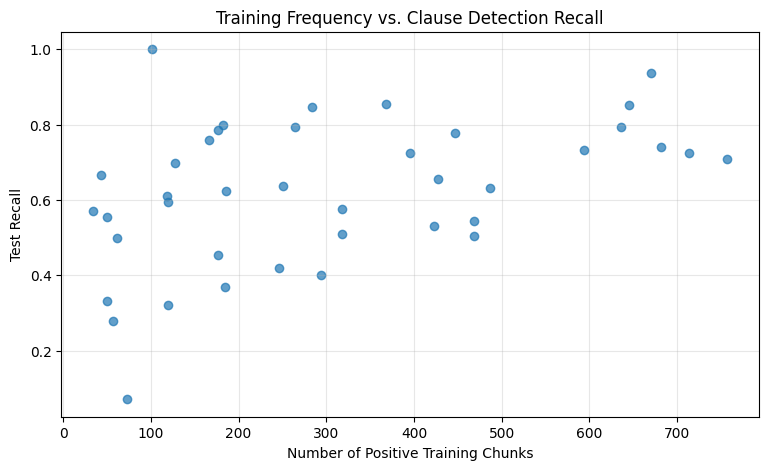

In [27]:
from scipy.stats import spearmanr

# Calculate the correlation between training frequency and recall
valid_data = frequency_analysis.dropna(
    subset=["train_positives", "recall"]
)

correlation, p_value = spearmanr(
    valid_data["train_positives"],
    valid_data["recall"]
)

print("Spearman correlation:", round(correlation, 4))
print("P-value:", round(p_value, 4))

# Visualize the relationship
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(
    valid_data["train_positives"],
    valid_data["recall"],
    alpha=0.7
)

plt.xlabel("Number of Positive Training Chunks")
plt.ylabel("Test Recall")
plt.title("Training Frequency vs. Clause Detection Recall")
plt.grid(alpha=0.3)

plt.show()

### Finding: Relationship Between Training Frequency and Recall

To investigate whether class imbalance is associated with model
performance, Spearman rank correlation was calculated between
the number of positive training chunks and test recall across
clause categories.

**Results:**
- Spearman correlation: 0.4133
- P-value: 0.008

The results indicate a moderate positive association between
training frequency and recall. Categories with more positive
training examples generally tend to achieve higher recall.

The relationship is statistically significant at the 5% level,
providing evidence that training frequency is associated with
the model's ability to detect clauses.

However, correlation does not establish causation. Differences
in clause complexity, wording, and annotation consistency may
also influence performance.

**Implication:**

Increasing the representation of underperforming clause
categories during training may be worth investigating as a
potential model improvement.

In [28]:
total_fp = int(error_summary["false_positives"].sum())
total_fn = int(error_summary["false_negatives"].sum())

print("Total false positives:", total_fp)
print("Total false negatives:", total_fn)
print("Total classification errors:", total_fp + total_fn)

print(
    "Percentage of errors that are false negatives:",
    round(100 * total_fn / (total_fp + total_fn), 2)
)

Total false positives: 1124
Total false negatives: 906
Total classification errors: 2030
Percentage of errors that are false negatives: 44.63


### Finding: Overall Error Distribution

Across the 4,283 test chunks and 40 clause categories, the model
produced 2,030 classification errors:

- False positives: 1,124 (55.37%)
- False negatives: 906 (44.63%)

False positives account for a slightly larger proportion of
the model's errors.

However, the relative importance of each error type depends
on its practical consequences.

In contract review, false positives may increase manual review
work, while false negatives may cause important legal provisions
to be overlooked.

These counts represent chunk-category prediction errors rather
than distinct contractual provisions.

## 4. False Positive Analysis

### Investigating Incorrect Clause Predictions

While false negatives represent missed clauses, false positives
occur when the model predicts a clause category that is not
present in the ground-truth labels.

We examine false-positive examples to investigate whether
incorrect predictions are associated with similar legal
concepts, surrounding contractual language, or potential
annotation inconsistencies.

We begin with the Effective Date category because it has
a relatively high number of false-positive predictions.

In [30]:
# Select a category with many false positives
target_fp_category = "Effective Date"

fp_category_idx = category_names.index(target_fp_category)

# Find chunks incorrectly predicted as Effective Date
fp_indices = np.where(
    (test_labels[:, fp_category_idx] == 0) &
    (test_predictions[:, fp_category_idx] == 1)
)[0]

print("Category:", target_fp_category)
print("Number of false positives:", len(fp_indices))

# Examine the three highest-confidence false positives
top_fp_indices = sorted(
    fp_indices,
    key=lambda idx: test_probs[idx, fp_category_idx],
    reverse=True
)[:3]

for idx in top_fp_indices:
    row = test_chunks.iloc[idx]

    print("=" * 80)
    print("Test row:", idx)
    print("Contract:", row["contract_id"])
    print("Chunk ID:", row["chunk_id"])

    print(
        "Predicted probability:",
        round(float(test_probs[idx, fp_category_idx]), 4)
    )

    print("Threshold:",
          round(float(category_thresholds[fp_category_idx]), 4))

    print("Actual labels:", row["labels"])

    print("\nContract text:")
    print(row["text"][:1500])
    print()

Category: Effective Date
Number of false positives: 88
Test row: 2196
Contract: GridironBionutrientsInc_20171206_8-K_EX-10.1_10972555_EX-10.1_Endorsement Agreement
Chunk ID: 0
Predicted probability: 0.9972
Threshold: 0.698
Actual labels: ["Agreement Date", "Document Name", "License Grant", "Parties"]

Contract text:
EXHIBIT 10.1   ENDORSEMENT AGREEMENT   This Endorsement Agreement ("Agreement") made October 30, 2017, between National Football League Alumni - Northern California Chapter ("NFLA-NC"), a charitable corporation organized under the laws of California, having its principal office at 1311 Madison Avenue, Redwood CA 94061; National Football League Alumni, Inc. ("NFLA"), a charitable corporation organized under the laws of Florida, having its principal office at 8000 Midlantic Drive, 130 S., Mount Laurel, NJ. 08054 and Food For Athletes, Inc. a corporation organized under the laws of California / Gridiron BioNutrients™, a corporation organized under the laws of Nevada having the

### Finding: Confusion Between Related Date Categories

Examination of high-confidence Effective Date false positives
revealed potential confusion between Effective Date and
Agreement Date.

**Example 1: Gridiron BioNutrients Endorsement Agreement**
- Actual label: Agreement Date
- Incorrect prediction: Effective Date
- Predicted probability: 0.9972
- Relevant language: "This Endorsement Agreement ... made October 30, 2017"

**Example 2: Bolivar Mining Agreement**
- Actual label: Agreement Date
- Incorrect prediction: Effective Date
- Predicted probability: 0.9941
- Relevant language: "This Agreement is made on this 12th day of May 2003"

Both examples contain agreement execution dates rather than
explicitly identified effective dates.

**Interpretation:**

The model may have difficulty distinguishing between closely
related legal concepts, particularly when their wording is similar.

These results suggest that category-specific training examples
and clearer distinctions between related clause types may help
improve classification performance.

In [31]:
# Examine the actual labels of Effective Date false positives
fp_label_lists = test_chunks.iloc[fp_indices]["labels"].apply(json.loads)

agreement_date_count = sum(
    "Agreement Date" in labels
    for labels in fp_label_lists
)

expiration_date_count = sum(
    "Expiration Date" in labels
    for labels in fp_label_lists
)

print("Total Effective Date false positives:", len(fp_indices))
print("Also labeled Agreement Date:", agreement_date_count)
print("Also labeled Expiration Date:", expiration_date_count)

print(
    "Percentage also labeled Agreement Date:",
    round(100 * agreement_date_count / len(fp_indices), 2)
)

Total Effective Date false positives: 88
Also labeled Agreement Date: 41
Also labeled Expiration Date: 16
Percentage also labeled Agreement Date: 46.59


### Finding: Systematic Confusion Between Date Categories

To determine whether confusion between Effective Date and
Agreement Date was widespread, we examined the ground-truth
labels of all 88 Effective Date false-positive chunks.

**Results:**
- 41 of 88 (46.59%) were labeled Agreement Date.
- 16 of 88 (18.18%) were labeled Expiration Date.

Nearly half of Effective Date false positives occurred in
chunks containing an Agreement Date annotation.

This suggests that the model may struggle to distinguish
between related contractual date concepts.

However, because chunks can contain multiple labels, these
results establish co-occurrence rather than proving that
Agreement Date language directly caused the incorrect
Effective Date predictions.

**Potential improvement:**

Investigate targeted training examples that explicitly
distinguish Agreement Date, Effective Date, and Expiration
Date, particularly in contracts containing multiple dates.

In [32]:
# Find Agreement Date false positives
agreement_idx = category_names.index("Agreement Date")

agreement_fp_indices = np.where(
    (test_labels[:, agreement_idx] == 0) &
    (test_predictions[:, agreement_idx] == 1)
)[0]

# Count how many actually contain Effective Date
reverse_confusion_count = sum(
    test_labels[idx, category_names.index("Effective Date")] == 1
    for idx in agreement_fp_indices
)

print("Total Agreement Date false positives:", len(agreement_fp_indices))
print("Also labeled Effective Date:", reverse_confusion_count)

if len(agreement_fp_indices) > 0:
    print(
        "Percentage also labeled Effective Date:",
        round(
            100 * reverse_confusion_count / len(agreement_fp_indices),
            2
        )
    )

Total Agreement Date false positives: 28
Also labeled Effective Date: 5
Percentage also labeled Effective Date: 17.86


### Finding: Asymmetric Confusion Between Date Categories

We also examined whether the model incorrectly predicts
Agreement Date in chunks labeled Effective Date.

**Results:**
- 28 Agreement Date false positives occurred.
- 5 of these (17.86%) contained an Effective Date annotation.
- In comparison, 41 of 88 Effective Date false positives
  (46.59%) contained an Agreement Date annotation.

The results suggest an asymmetric pattern of confusion
between the two categories.

The model appears particularly prone to predicting
Effective Date in chunks containing Agreement Date.

One possible explanation is that the model has learned
an overly broad interpretation of Effective Date.

However, these results measure label co-occurrence among
false positives rather than direct clause-level confusion.

**Potential improvement:**

Use targeted examples containing both date concepts to
help the model learn the distinction between agreement
execution dates and effective dates.

In [33]:
# Collect probabilities for all false-positive predictions
fp_mask = (test_predictions == 1) & (test_labels == 0)

fp_confidences = test_probs[fp_mask]

print("Total false positives:", len(fp_confidences))
print("Average FP confidence:", round(fp_confidences.mean(), 4))
print("Median FP confidence:", round(np.median(fp_confidences), 4))

print(
    "False positives with probability >= 0.90:",
    int((fp_confidences >= 0.90).sum())
)

print(
    "Percentage with probability >= 0.90:",
    round(100 * (fp_confidences >= 0.90).mean(), 2)
)

Total false positives: 1124
Average FP confidence: 0.8268
Median FP confidence: 0.8687
False positives with probability >= 0.90: 467
Percentage with probability >= 0.90: 41.55


### Finding: High-Confidence False Positive Predictions

We analyzed the predicted probabilities associated with all
1,124 false-positive classifications.

**Results:**
- Average false-positive probability: 0.8268
- Median false-positive probability: 0.8687
- False positives with probability >= 0.90: 467 (41.55%)

A substantial proportion of incorrect predictions received
high probability scores.

This suggests that the model's errors are not limited to
borderline predictions near classification thresholds.

For example, the model incorrectly predicted Effective Date
in an Agreement Date chunk with a probability of 0.9972.

**Implication:**

High predicted probabilities do not guarantee correct clause
identification. A contract review system should not rely
exclusively on model confidence when determining whether a
clause is present.

Further calibration analysis and targeted evaluation of
high-confidence errors may help identify opportunities
for improvement.

In [34]:
# Identify false-negative predictions
fn_mask = (test_predictions == 0) & (test_labels == 1)

# Get predicted probabilities for missed clauses
fn_confidences = test_probs[fn_mask]

print("Total false negatives:", len(fn_confidences))
print("Average FN probability:", round(fn_confidences.mean(), 4))
print("Median FN probability:", round(np.median(fn_confidences), 4))

print(
    "False negatives with probability below 0.10:",
    int((fn_confidences < 0.10).sum())
)

print(
    "Percentage with probability below 0.10:",
    round(100 * (fn_confidences < 0.10).mean(), 2)
)

Total false negatives: 906
Average FN probability: 0.251
Median FN probability: 0.1592
False negatives with probability below 0.10: 383
Percentage with probability below 0.10: 42.27


### Finding: Low-Confidence Predictions for Missed Clauses

We examined the predicted probabilities associated with
all 906 false-negative classifications.

**Results:**
- Average false-negative probability: 0.2510
- Median false-negative probability: 0.1592
- False negatives with probability below 0.10: 383 (42.27%)

A substantial proportion of missed clauses received very
low predicted probabilities.

This suggests that some false negatives may result from
the model failing to recognize relevant clause language,
rather than simply assigning probabilities slightly below
the classification threshold.

Combined with the high-confidence false-positive findings,
these results indicate that the model makes both strongly
incorrect positive predictions and very low-scoring
predictions for genuinely present categories.

**Implication:**

Adjusting classification thresholds may improve performance,
but additional training improvements may be necessary.

Potential approaches include targeted training examples,
class imbalance mitigation, and improved differentiation
between similar clause categories.

In [35]:
# Calculate the distance between each prediction and its category threshold
threshold_distances = category_thresholds[None, :] - test_probs

# Only examine false negatives
fn_distances = threshold_distances[fn_mask]

print("Average distance below threshold:", round(fn_distances.mean(), 4))
print("Median distance below threshold:", round(np.median(fn_distances), 4))

# Count missed predictions that were close to their thresholds
near_threshold = (fn_distances <= 0.10).sum()

print("False negatives within 0.10 of threshold:", int(near_threshold))
print(
    "Percentage within 0.10 of threshold:",
    round(100 * near_threshold / len(fn_distances), 2)
)

Average distance below threshold: 0.4712
Median distance below threshold: 0.4803
False negatives within 0.10 of threshold: 106
Percentage within 0.10 of threshold: 11.7


### Finding: Most False Negatives Are Far Below Their Classification Thresholds

To determine whether missed clauses were primarily caused by
restrictive classification thresholds, we calculated the
distance between each false-negative prediction and its
category-specific threshold.

**Results:**
- Average distance below threshold: 0.4712
- Median distance below threshold: 0.4803
- False negatives within 0.10 of threshold: 106 (11.70%)
- False negatives more than 0.10 below threshold: 800 (88.30%)

Most missed clauses received probability scores substantially
below their classification thresholds.

This suggests that many false negatives reflect difficulties
recognizing clause language rather than borderline threshold
decisions.

**Implication:**

Threshold tuning alone may not adequately address these
errors. Improvements to training data representation,
recognition of rare clause types, and differentiation between
similar legal concepts should also be investigated.

In [36]:
# Calculate average distance below threshold for each category
fn_distance_summary = []

for i, category in enumerate(category_names):
    category_fn_mask = fn_mask[:, i]

    if category_fn_mask.sum() == 0:
        continue

    distances = (
        category_thresholds[i]
        - test_probs[category_fn_mask, i]
    )

    fn_distance_summary.append({
        "category": category,
        "false_negatives": int(category_fn_mask.sum()),
        "avg_distance_below_threshold": distances.mean(),
        "median_distance_below_threshold": np.median(distances)
    })

fn_distance_df = pd.DataFrame(fn_distance_summary)

display(
    fn_distance_df.sort_values(
        "avg_distance_below_threshold",
        ascending=False
    ).head(10)
)

,category,false_negatives,avg_distance_below_threshold,median_distance_below_threshold
17,Joint Ip Ownership,7,0.789334,0.784128
26,Notice Period To Terminate Renewal,6,0.754830,0.861281
32,Source Code Escrow,1,0.712252,0.712252
15,Ip Ownership Assignment,45,0.694630,0.799903
24,Non-Disparagement,13,0.596782,0.715652
2,Agreement Date,25,0.593767,0.612061
22,No-Solicit Of Customers,8,0.583216,0.627082
9,Document Name,48,0.582334,0.753039
35,Uncapped Liability,4,0.570554,0.565044
27,Parties,36,0.564201,0.698418


### Finding: Categories With Severe False-Negative Errors

We calculated how far each false-negative prediction fell
below its category-specific classification threshold.

Several categories exhibited particularly large prediction gaps.

**Notable findings:**
- Joint Ip Ownership: 7 false negatives, average gap 0.7893
- Ip Ownership Assignment: 45 false negatives, average gap 0.6946
- Non-Disparagement: 13 false negatives, average gap 0.5968
- Agreement Date: 25 false negatives, average gap 0.5938
- Document Name: 48 false negatives, average gap 0.5823

Ip Ownership Assignment is particularly notable because it
combines a relatively large number of missed predictions
with a substantial average distance below its threshold.

Non-Disparagement also remains a major concern, consistent
with our earlier qualitative analysis.

These findings suggest that certain categories may require
improvements beyond classification threshold adjustments.

However, threshold distances are influenced by the
category-specific thresholds and should not be interpreted
as a direct measure of error severity across categories.

**Potential improvement:**

Prioritize targeted error analysis and training improvements
for categories with both high false-negative counts and
large prediction gaps.

In [38]:
# Combine category-level error statistics with training frequency
priority_analysis = error_summary.merge(
    frequency_analysis[["category", "train_positives", "recall", "f1"]],
    on="category",
    how="left"
)

priority_analysis = priority_analysis.merge(
    fn_distance_df[["category", "avg_distance_below_threshold"]],
    on="category",
    how="left"
)

# Focus on categories with at least 10 actual positive test chunks
priority_analysis = priority_analysis[
    priority_analysis["actual_positives"] >= 10
].copy()

# Rank by false-negative rate, then number of false negatives
priority_analysis = priority_analysis.sort_values(
    ["false_negative_rate", "false_negatives"],
    ascending=[False, False]
)

display(
    priority_analysis[
        [
            "category",
            "train_positives",
            "actual_positives",
            "false_negatives",
            "false_negative_rate",
            "avg_distance_below_threshold"
        ]
    ].head(10).round(3)
)

,category,train_positives,actual_positives,false_negatives,false_negative_rate,avg_distance_below_threshold
25,Non-Disparagement,73,14.0,13,0.929,0.597
1,Affiliate License-Licensor,57,18.0,13,0.722,0.384
0,Affiliate License-Licensee,120,28.0,19,0.679,0.468
38,Volume Restriction,184,38.0,24,0.632,0.535
15,Ip Ownership Assignment,294,75.0,45,0.600,0.695
6,Change Of Control,246,74.0,43,0.581,0.469
8,Covenant Not To Sue,176,66.0,36,0.545,0.478
22,No-Solicit Of Customers,61,16.0,8,0.500,0.583
29,Post-Termination Services,468,101.0,50,0.495,0.465
26,Non-Transferable License,318,57.0,28,0.491,0.447


## 5. Model Improvement Priorities

### Identifying High-Priority Clause Categories

We combined training frequency, false-negative rates, and
prediction-threshold distances to identify categories
requiring further investigation.

Two major patterns emerged.

**1. Rare categories with high miss rates**

- Non-Disparagement: 73 training chunks, 92.9% miss rate
- Affiliate License-Licensor: 57 training chunks, 72.2% miss rate
- Affiliate License-Licensee: 120 training chunks, 67.9% miss rate

These results suggest that limited positive training
examples may contribute to poor detection performance.

**2. Categories with substantial training data but poor recall**

- Ip Ownership Assignment: 294 training chunks, 60.0% miss rate
- Change Of Control: 246 training chunks, 58.1% miss rate
- Post-Termination Services: 468 training chunks, 49.5% miss rate

These categories have more training examples but still
experience substantial detection failures.

This suggests that class imbalance alone cannot explain
the model's weaknesses. Clause complexity, wording
variation, and overlapping legal concepts may also
contribute.

### Recommended Areas for Improvement

1. Investigate class-weighted loss functions or targeted
   sampling for underrepresented clause categories.

2. Examine additional false-negative examples from
   high-error categories to identify recurring language
   patterns.

3. Improve differentiation between related categories,
   particularly Agreement Date and Effective Date.

4. Evaluate threshold adjustments using validation data,
   while monitoring the tradeoff between precision and recall.

5. Investigate whether overlapping chunks produce
   redundant errors and consider evaluating performance
   at the clause or contract level.

These recommendations are hypotheses for future
experiments rather than confirmed solutions.

In [39]:
# Count false negatives and false positives for each test chunk
chunk_error_analysis = test_chunks[
    ["contract_id", "chunk_id"]
].copy()

chunk_error_analysis["false_negatives"] = fn_mask.sum(axis=1)
chunk_error_analysis["false_positives"] = fp_mask.sum(axis=1)

chunk_error_analysis["total_errors"] = (
    chunk_error_analysis["false_negatives"]
    + chunk_error_analysis["false_positives"]
)

# Aggregate errors by contract
contract_error_summary = (
    chunk_error_analysis
    .groupby("contract_id")
    .agg(
        num_chunks=("chunk_id", "count"),
        false_negatives=("false_negatives", "sum"),
        false_positives=("false_positives", "sum"),
        total_errors=("total_errors", "sum")
    )
    .reset_index()
)

contract_error_summary["errors_per_chunk"] = (
    contract_error_summary["total_errors"]
    / contract_error_summary["num_chunks"]
)

display(
    contract_error_summary.sort_values(
        "total_errors", ascending=False
    ).head(10).round(3)
)

,contract_id,num_chunks,false_negatives,false_positives,total_errors,errors_per_chunk
28,"GOOSEHEADINSURANCE,INC_04_02_2018-EX-10.6-Fran...",252,45,113,158,0.627
52,Monsanto Company - SECOND A_R EXCLUSIVE AGENCY...,183,32,52,84,0.459
39,HarpoonTherapeuticsInc_20200312_10-K_EX-10.18_...,221,31,51,82,0.371
84,SoupmanInc_20150814_8-K_EX-10.1_9230148_EX-10....,123,32,41,73,0.593
59,"PACIRA PHARMACEUTICALS, INC. - A_R STRATEGIC L...",133,38,34,72,0.541
54,MusclepharmCorp_20170208_10-KA_EX-10.38_989358...,74,18,48,66,0.892
29,GRANTIERRAENERGYINC_05_07_2012-EX-10.6-TRANSPO...,212,26,30,56,0.264
7,"BABCOCK_WILCOXENTERPRISES,INC_08_04_2015-EX-10...",92,19,32,51,0.554
36,"HEMISPHERX - Sales, Marketing, Distribution, a...",64,24,24,48,0.750
20,DovaPharmaceuticalsInc_20181108_10-Q_EX-10.2_1...,153,19,26,45,0.294


## 6. Contract-Level Error Analysis

### Finding: Errors Are Concentrated in Certain Contracts

We aggregated false-positive and false-negative predictions
by contract to investigate whether classification errors
were distributed evenly across documents.

**Notable findings:**

- Goosehead Insurance: 158 errors across 252 chunks
  (0.627 errors per chunk).
- Monsanto: 84 errors across 183 chunks
  (0.459 errors per chunk).
- Harpoon Therapeutics: 82 errors across 221 chunks
  (0.371 errors per chunk).
- MusclePharm: 66 errors across 74 chunks
  (0.892 errors per chunk).
- Hemispherx: 48 errors across 64 chunks
  (0.750 errors per chunk).

Goosehead Insurance contributed the largest number of
classification errors among the contracts examined.

However, MusclePharm and Hemispherx exhibited higher
error concentrations relative to their chunk counts.

These results suggest that contract length alone does
not explain the distribution of errors.

Differences in contractual language, clause structure,
and annotation patterns may also contribute.

**Limitations:**

Because the model uses overlapping text chunks, some
errors may represent repeated predictions involving
the same underlying contractual language.

Additionally, errors per chunk measures the average
number of incorrect category predictions rather than
the percentage of incorrectly classified chunks.

**Potential improvement:**

Investigate high-error contracts individually and
evaluate whether document-level context or alternative
chunking strategies improve performance.

In [40]:
# Identify chunks with at least one classification error
chunks_with_errors = (
    chunk_error_analysis["total_errors"] > 0
).sum()

total_chunks = len(chunk_error_analysis)

print("Total test chunks:", total_chunks)
print("Chunks with at least one error:", chunks_with_errors)

print(
    "Percentage of chunks with errors:",
    round(100 * chunks_with_errors / total_chunks, 2)
)

print(
    "Chunks with no classification errors:",
    total_chunks - chunks_with_errors
)

Total test chunks: 4283
Chunks with at least one error: 1375
Percentage of chunks with errors: 32.1
Chunks with no classification errors: 2908


### Finding: Chunk-Level Classification Accuracy

We evaluated how frequently the model correctly classified
all 40 clause categories for an entire test chunk.

**Results:**
- Total test chunks: 4,283
- Chunks with at least one classification error: 1,375 (32.10%)
- Chunks with no classification errors: 2,908 (67.90%)

The model correctly classified every category for approximately
68% of test chunks.

However, nearly one-third of chunks contained at least one
incorrect category prediction.

This is a strict exact-match measure because a single incorrect
category prediction causes the entire chunk to be counted
as incorrect.

These results should be considered alongside category-level
precision, recall, and F1 scores, particularly because many
categories are absent from individual chunks.

## 7. Final Conclusions and Recommendations

### Summary of Key Findings

This analysis evaluated the DistilRoBERTa clause-classification
model using 4,283 test chunks across 40 clause categories.

**1. Overall Classification Errors**
- 2,030 total chunk-category errors
- 1,124 false positives (55.37%)
- 906 false negatives (44.63%)
- 32.10% of test chunks contained at least one error

**2. Class Imbalance**
- Training frequency and recall exhibited a moderate positive
  association (Spearman correlation = 0.4133, p = 0.008).
- Rare categories such as Non-Disparagement and Affiliate
  License categories experienced particularly high miss rates.
- However, several categories with more training examples
  also performed poorly, suggesting class imbalance is not
  the only contributing factor.

**3. Confusion Between Similar Categories**
- 46.59% of Effective Date false positives occurred in chunks
  containing an Agreement Date annotation.
- This suggests possible confusion between related legal
  concepts, particularly contractual date categories.

**4. High-Confidence Classification Errors**
- 41.55% of false positives had predicted probabilities
  of at least 0.90.
- 42.27% of false negatives received probabilities below 0.10.
- Only 11.70% of false negatives were within 0.10 of their
  category-specific classification thresholds.

These findings suggest that classification threshold tuning
alone may not resolve the model's recognition weaknesses.

**5. Contract-Level Error Concentration**
- Some contracts contributed substantially more errors than
  others, even after accounting for the number of chunks.
- Overlapping chunks may also cause individual clause-level
  mistakes to appear multiple times.

### Recommended Next Steps

**Priority 1: Improve Rare Category Detection**

Investigate class-weighted loss functions, targeted sampling,
and additional training examples for categories such as
Non-Disparagement and Affiliate License.

**Priority 2: Investigate Difficult Clause Categories**

Review false negatives for Ip Ownership Assignment,
Change Of Control, and Post-Termination Services to identify
recurring language patterns and possible recognition failures.

**Priority 3: Reduce Confusion Between Related Categories**

Evaluate targeted training examples that distinguish
Agreement Date, Effective Date, and other similar concepts.

**Priority 4: Evaluate Thresholds and Confidence**

Use validation data to investigate alternative thresholds,
precision-recall tradeoffs, and probability calibration.

**Priority 5: Improve Evaluation Beyond Individual Chunks**

Investigate clause-level and contract-level evaluation to
reduce the influence of overlapping windows and better
reflect real-world contract review performance.

### Overall Conclusion

The model demonstrates the ability to classify many contract
chunks correctly, but its performance varies substantially
across clause categories.

The most important weaknesses involve rare clause detection,
confusion between related legal concepts, and missed clauses
receiving probabilities far below their classification thresholds.

Future improvements should prioritize better recognition of
difficult clause types while maintaining appropriate precision
and recall for practical contract review applications.